# Análisis exploratorio · Sistema de tickets TI con IA

Sprint 1, paso 5. Usa las funciones de `src/data/eda.py`; el informe escrito está en `reports/eda.md`.

In [1]:
import sys; sys.path.insert(0, '..')
import pandas as pd
from IPython.display import Image, display
from src.data import eda
from src.data.eda import FIGURAS
df = eda.cargar()
print(len(df), 'tickets;', int(df.real.sum()), 'reales')
df.head(3)

9379 tickets; 8834 reales


,id,fuente,idioma_original,texto_original,titulo,descripcion,categoria,prioridad,impacto,urgencia,usuarios_afectados,solucion,origen_etiqueta,origen_categoria,origen_prioridad,excepcion_matriz,grupo,real,palabras,subconjunto
0,TS-TCKT-10001,tech_support,en,Application crashes upon startup after latest ...,La aplicación se bloquea al iniciar después de...,La aplicación se bloquea al iniciar después de...,Software,Alta,Alto,Media,200.0,Software parcheado y cliente guiado a través d...,fuente,fuente,fuente,False,TS-TCKT-10001,True,11,train
1,TS-TCKT-10002,tech_support,en,Unable to connect to corporate VPN from home.,No se puede conectar a VPN corporativa desde c...,No se puede conectar a VPN corporativa desde c...,Red,Media,Medio,Media,30.0,,fuente,fuente,fuente,False,TS-TCKT-10002,True,9,train
2,TS-TCKT-10003,tech_support,en,Laptop keyboard is not responding intermittently.,El teclado portátil no responde intermitenteme...,El teclado portátil no responde intermitenteme...,Hardware,Alta,Medio,Alta,30.0,,fuente,fuente,fuente,False,TS-TCKT-10003,True,6,val


## Categorías y prioridades

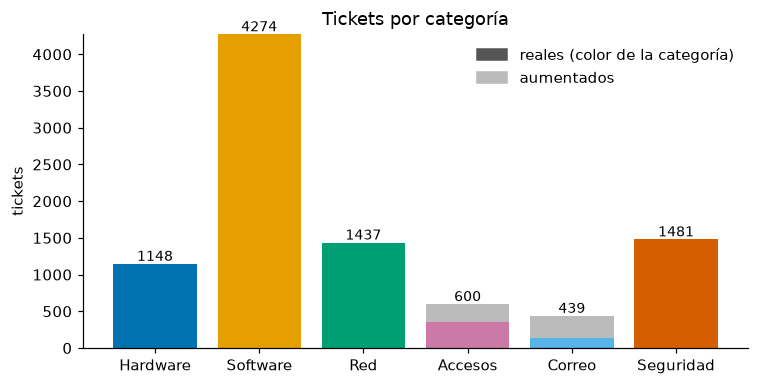

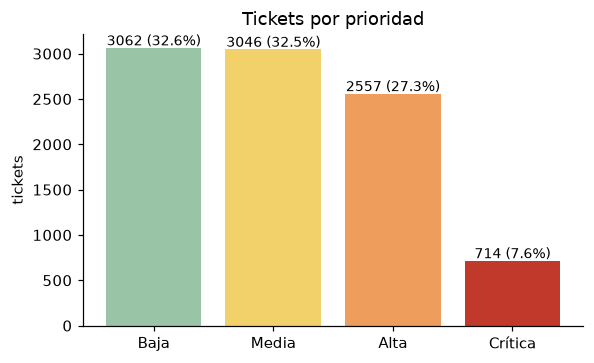

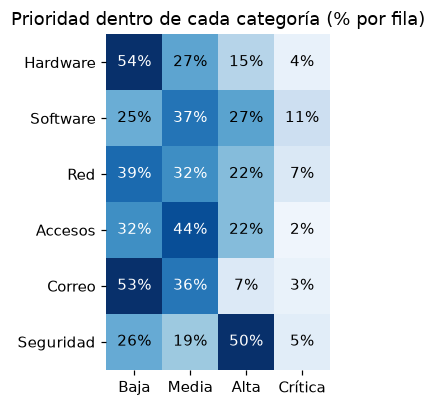

In [2]:
for fn in (eda.fig_categorias, eda.fig_prioridades, eda.fig_cruce):
    display(Image(str(FIGURAS.parent / fn(df))))

In [3]:
pd.crosstab(df.categoria, df.prioridad, margins=True)

prioridad,Alta,Baja,Crítica,Media,All
categoria,,,,,
Accesos,131,191,12,266,600
Correo,30,234,15,160,439
Hardware,172,623,42,311,1148
Red,313,558,106,460,1437
Seguridad,742,381,80,278,1481
Software,1169,1075,459,1571,4274
All,2557,3062,714,3046,9379


## Fuentes y longitud de los textos

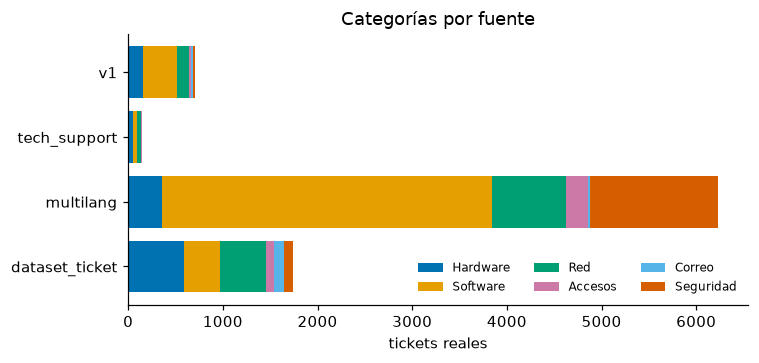

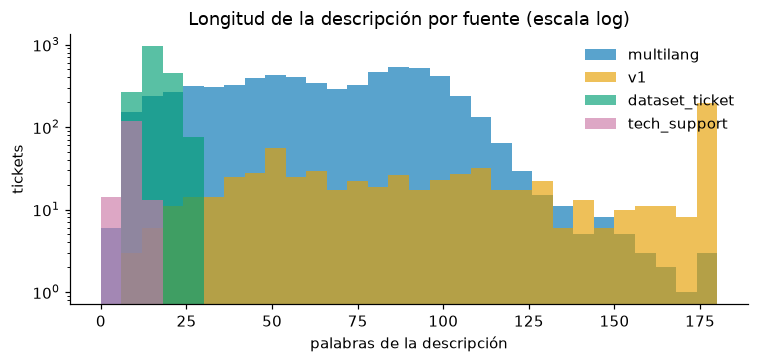

,count,mean,std,min,25%,50%,75%,max
fuente,,,,,,,,
dataset_ticket,1745.0,15.6,4.1,7.0,13.0,15.0,18.0,29.0
multilang,6235.0,63.9,29.5,4.0,40.0,64.0,88.0,187.0
tech_support,145.0,8.2,2.2,4.0,7.0,8.0,9.0,15.0
v1,709.0,121.2,73.9,8.0,58.0,105.0,180.0,377.0


In [4]:
for fn in (eda.fig_fuente_categoria, eda.fig_longitud):
    display(Image(str(FIGURAS.parent / fn(df))))
df[df.real].groupby('fuente').palabras.describe().round(1)

## Impacto y urgencia

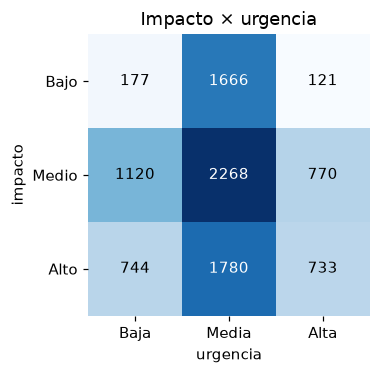

In [5]:
display(Image(str(FIGURAS.parent / eda.fig_impacto_urgencia(df))))

## Vocabulario y términos distintivos (train)

In [6]:
print('palabras distintas, con ≥2 apariciones, OOV en test:', eda.vocabulario(df))
pd.Series({c: ', '.join(t) for c, t in eda.terminos_distintivos(df).items()})

palabras distintas, con ≥2 apariciones, OOV en test: (8351, 6089, np.float64(0.013246677981537442))


Hardware     teclado, computadora, monitor, ratón, memoria,...
Software     análisis, integración, plataforma, saas, gesti...
Red          conexión, conectividad, router, problemas, dis...
Accesos      sesión, inicio, acceso, permiso, servidor, usu...
Correo       correos, electrónicos, correo, electrónico, al...
Seguridad    seguridad, médicos, datos, acceso, sistemas, v...
dtype: str

## Ejemplos reales por categoría

In [7]:
pd.set_option('display.max_colwidth', 160)
df[df.real].groupby('categoria').sample(2, random_state=42)[['categoria', 'prioridad', 'fuente', 'titulo', 'descripcion']]

,categoria,prioridad,fuente,titulo,descripcion
5553,Accesos,Media,multilang,Informe del problema,"Atención al cliente,\nMe estoy enfrentando a dificultades con el proceso centralizado de administración de cuentas. Aunque las características parecen estar..."
926,Accesos,Alta,multilang,Problema con la plataforma de inicio de sesión,"Los usuarios se enfrentan a problemas ocasionales de inicio de sesión en la plataforma, que podrían estar relacionados con actualizaciones recientes del ser..."
7364,Correo,Baja,dataset_ticket,"Los correos electrónicos enviados no se guardan en la carpeta Enviado, lo que dificulta el seguimiento de las…","Los correos electrónicos enviados no se guardan en la carpeta Enviado, lo que dificulta el seguimiento de las comunicaciones."
8651,Correo,Media,v1,Espero que este correo electrónico los encuentre bien.,"Estimado equipo de soporte al cliente, Espero que este correo electrónico los encuentre bien. Les escribo para solicitar asistencia con el proyecto en curso..."
7726,Hardware,Baja,dataset_ticket,No puedo escribir el símbolo at en mi teclado a pesar de pulsar el botón correcto.,No puedo escribir el símbolo at en mi teclado a pesar de pulsar el botón correcto.
7485,Hardware,Media,dataset_ticket,"Los juegos que solía ejecutar sin problemas ahora tienen caídas repentinas de las cuotas de marcos, creo que…","Los juegos que solía ejecutar sin problemas ahora tienen caídas repentinas de las cuotas de marcos, creo que la CPU no está al máximo del rendimiento."
4166,Red,Media,multilang,Edición con Startup of Project Management Dashboards,"Estimado servicio de atención al cliente, he estado experimentando problemas de carga intermitentes con el panel de control de gestión de proyectos. Posible..."
2016,Red,Alta,multilang,Problemas con el soporte de conexión WLAN,"Estimado Servicio al Cliente, estoy encontrando problemas de conexión con el programa SaaS en múltiples dispositivos. El problema parece derivar de la inest..."
5484,Seguridad,Alta,multilang,"El sistema de salud del hospital experimentó una violación no autorizada, poniendo en riesgo la seguridad de…","El sistema de salud del hospital experimentó una violación no autorizada, poniendo en riesgo la seguridad de los datos médicos. Se está considerando un pres..."
1372,Seguridad,Alta,multilang,Me dirijo a usted para informar de una cuestión grave relativa a una violación de datos que ha comprometido…,"Atención al cliente,\nMe dirijo a usted para informar de una cuestión grave relativa a una violación de datos que ha comprometido el acceso a información mé..."


## Distribución en train / val / test

In [8]:
pd.concat({'categoria': pd.crosstab(df.subconjunto, df.categoria, normalize='index').round(3), 'prioridad': pd.crosstab(df.subconjunto, df.prioridad, normalize='index').round(3)}, axis=1)

categoria                                           prioridad  \
              Accesos Correo Hardware    Red Seguridad Software      Alta   
subconjunto                                                                 
test            0.064  0.049    0.123  0.152     0.157    0.454     0.272   
train           0.064  0.046    0.122  0.154     0.158    0.457     0.273   
val             0.064  0.049    0.123  0.152     0.158    0.453     0.272   

                                   
              Baja Crítica  Media  
subconjunto                        
test         0.325   0.078  0.324  
train        0.327   0.075  0.325  
val          0.325   0.078  0.324